In [2]:
import json
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SeparableConv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping


2025-05-13 14:54:06.921972: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-13 14:54:06.921995: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [4]:
# Load the preprocessed dataset
df = pd.read_csv('../../../Edge-IIoTset_DNN-112.csv')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [6]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [7]:
print(df['Attack_type'].value_counts())

Attack_type
Normal       1399624
DDoS          288112
Injection     102851
Malware        83648
Scanning       70856
MITM             358
Name: count, dtype: int64


In [8]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [9]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [10]:
print(df['Attack_type'].value_counts())

Attack_type
0    1399624
1     288112
3     102851
5      83648
2      70856
4        358
Name: count, dtype: int64


In [11]:
mi_scores = mutual_info_classif(X, y, discrete_features='auto', random_state=42)
mi_scores = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

In [12]:
# Print top features
print(mi_scores.head(10))

dns_0            0.788070
tcp.dstport      0.696608
mqtt3_0          0.652841
mqtt1_0          0.652655
mqtt2_0          0.652334
dns_encoded      0.630067
mqtt1_1          0.629818
dns_1            0.629320
mqtt3_encoded    0.614106
mqtt2_encoded    0.614053
dtype: float64


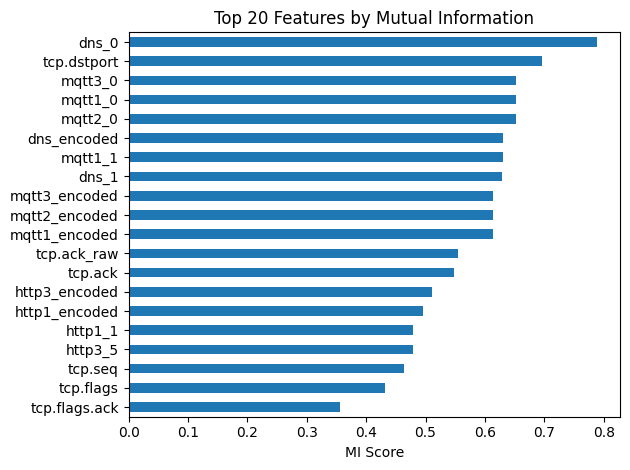

In [13]:
mi_scores.head(20).plot(kind='barh')
plt.title("Top 20 Features by Mutual Information")
plt.xlabel("MI Score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

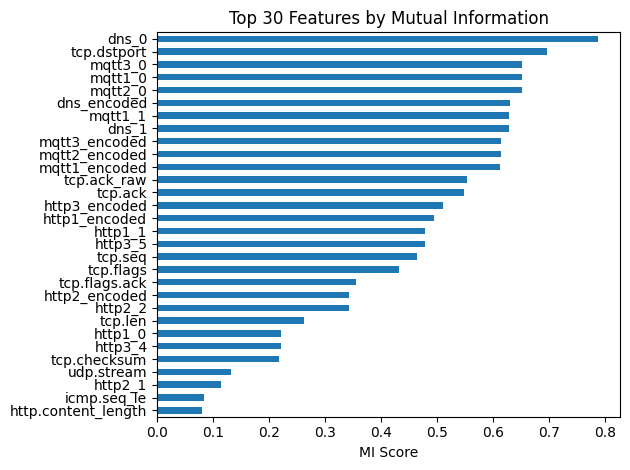

In [14]:
mi_scores.head(30).plot(kind='barh')
plt.title("Top 30 Features by Mutual Information")
plt.xlabel("MI Score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

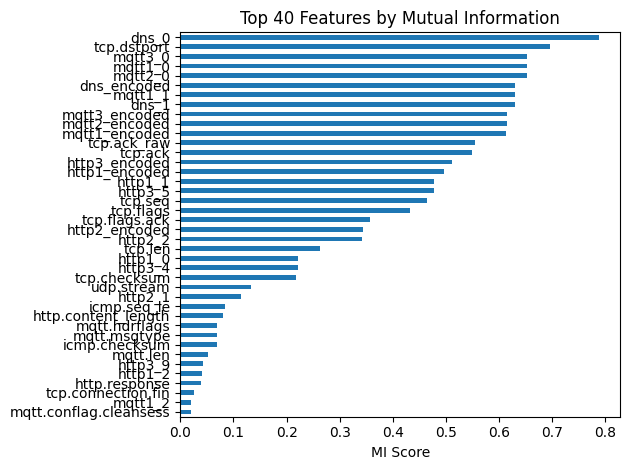

In [15]:
mi_scores.head(40).plot(kind='barh')
plt.title("Top 40 Features by Mutual Information")
plt.xlabel("MI Score")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [16]:
best_params = {
    "filters": 64,
    "kernel_size": 5,
    "dropout_rate": 0.3,
    "learning_rate": 0.0005,
    "l2_reg": 0.0001,
}

best_fit_params = {
    "batch_size": 32,
    "epochs": 25,
}

In [17]:
# Initialize the 1D CNN classifier
def model_1d_cnn(
        input_shape,
        num_classes=6,
        filters=64,
        kernel_size=3,
        pool_size=2,
        dropout_rate=0.5,
        dense_units=100,
        learning_rate=1e-3,
        optimizer="adam",
        l2_reg=0.0,
):
    _model = Sequential([
        SeparableConv1D(filters=filters,
                        kernel_size=kernel_size,
                        activation="relu",
                        kernel_regularizer=l2(l2_reg),
                        input_shape=input_shape),
        MaxPooling1D(pool_size=pool_size),
        Dropout(dropout_rate),
        Flatten(),
        Dense(dense_units, activation="relu"),
    ])

    if num_classes == 2:
        _model.add(Dense(1, activation="sigmoid"))
        loss = "binary_crossentropy"
    else:
        _model.add(Dense(num_classes, activation="softmax"))
        loss = "sparse_categorical_crossentropy"

    # choose optimiser
    if optimizer == "adam":
        opt = Adam(learning_rate=learning_rate)
    elif optimizer == "rmsprop":
        opt = RMSprop(learning_rate=learning_rate)
    elif optimizer == "sgd":
        opt = SGD(learning_rate=learning_rate, momentum=0.9)
    else:
        raise ValueError("Unknown optimiser.")

    _model.compile(optimizer=opt, loss=loss, metrics=["accuracy"])
    return _model

In [18]:
max_features = len(mi_scores)
feature_counts = list(range(10, max_features + 1, 10))  # e.g., 10, 20, ..., up to all features

results = []
num_classes = 6
for k in feature_counts:
    selected_features = mi_scores.head(k).index.tolist()
    X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)
    scaler = StandardScaler().fit(X_train)
    X_train = scaler.transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)
    input_shape = (X_train.shape[1], 1)
    model = model_1d_cnn(input_shape=input_shape,
                     num_classes=num_classes,
                     **best_params)
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
    history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=best_fit_params['epochs'],
                    batch_size=best_fit_params['batch_size'],
                    callbacks=[early_stop])
    val_acc = max(history.history['val_accuracy'])
    results.append((k, val_acc))

2025-05-13 15:21:02.970583: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-05-13 15:21:02.973795: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-05-13 15:21:02.973897: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-05-13 15:21:02.973959: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-05-13 15:21:02.974020: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

Epoch 1/25
42557/42557 [==============================] - 67s 2ms/step - loss: 0.2963 - accuracy: 0.8883 - val_loss: 0.2714 - val_accuracy: 0.9033
Epoch 2/25
42557/42557 [==============================] - 67s 2ms/step - loss: 0.2735 - accuracy: 0.9010 - val_loss: 0.2622 - val_accuracy: 0.9039
Epoch 3/25
42557/42557 [==============================] - 69s 2ms/step - loss: 0.2664 - accuracy: 0.9043 - val_loss: 0.2579 - val_accuracy: 0.9077
Epoch 4/25
42557/42557 [==============================] - 71s 2ms/step - loss: 0.2628 - accuracy: 0.9059 - val_loss: 0.2574 - val_accuracy: 0.9086
Epoch 5/25
42557/42557 [==============================] - 71s 2ms/step - loss: 0.2615 - accuracy: 0.9062 - val_loss: 0.2536 - val_accuracy: 0.9109
Epoch 6/25
42557/42557 [==============================] - 72s 2ms/step - loss: 0.2607 - accuracy: 0.9064 - val_loss: 0.2530 - val_accuracy: 0.9080
Epoch 7/25
42557/42557 [==============================] - 71s 2ms/step - loss: 0.2600 - accuracy: 0.9066 - val_loss: 0

2025-05-13 21:23:53.203424: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 435780480 exceeds 10% of free system memory.


Epoch 1/25
42557/42557 [==============================] - 173s 4ms/step - loss: 0.1010 - accuracy: 0.9575 - val_loss: 0.0787 - val_accuracy: 0.9637
Epoch 2/25
42557/42557 [==============================] - 170s 4ms/step - loss: 0.0803 - accuracy: 0.9645 - val_loss: 0.0757 - val_accuracy: 0.9667
Epoch 3/25
42557/42557 [==============================] - 171s 4ms/step - loss: 0.0751 - accuracy: 0.9652 - val_loss: 0.0733 - val_accuracy: 0.9665
Epoch 4/25
42557/42557 [==============================] - 171s 4ms/step - loss: 0.0741 - accuracy: 0.9659 - val_loss: 0.0715 - val_accuracy: 0.9686
Epoch 5/25
42557/42557 [==============================] - 170s 4ms/step - loss: 0.0725 - accuracy: 0.9671 - val_loss: 0.0680 - val_accuracy: 0.9721
Epoch 6/25
42557/42557 [==============================] - 171s 4ms/step - loss: 0.0703 - accuracy: 0.9684 - val_loss: 0.0660 - val_accuracy: 0.9721
Epoch 7/25
42557/42557 [==============================] - 171s 4ms/step - loss: 0.0677 - accuracy: 0.9692 - val_

2025-05-13 22:39:25.383703: W tensorflow/core/framework/cpu_allocator_impl.cc:82] Allocation of 490253040 exceeds 10% of free system memory.


Epoch 1/25
42557/42557 [==============================] - 198s 5ms/step - loss: 0.1093 - accuracy: 0.9556 - val_loss: 0.0877 - val_accuracy: 0.9597
Epoch 2/25
42557/42557 [==============================] - 212s 5ms/step - loss: 0.0902 - accuracy: 0.9608 - val_loss: 0.0775 - val_accuracy: 0.9652
Epoch 3/25
42557/42557 [==============================] - 204s 5ms/step - loss: 0.0805 - accuracy: 0.9639 - val_loss: 0.0801 - val_accuracy: 0.9656
Epoch 4/25
42557/42557 [==============================] - 208s 5ms/step - loss: 0.0780 - accuracy: 0.9643 - val_loss: 0.0737 - val_accuracy: 0.9655
Epoch 5/25
42557/42557 [==============================] - 208s 5ms/step - loss: 0.0762 - accuracy: 0.9645 - val_loss: 0.0777 - val_accuracy: 0.9656
Epoch 6/25
42557/42557 [==============================] - 212s 5ms/step - loss: 0.0759 - accuracy: 0.9646 - val_loss: 0.0737 - val_accuracy: 0.9655
Epoch 7/25
42557/42557 [==============================] - 205s 5ms/step - loss: 0.0766 - accuracy: 0.9647 - val_

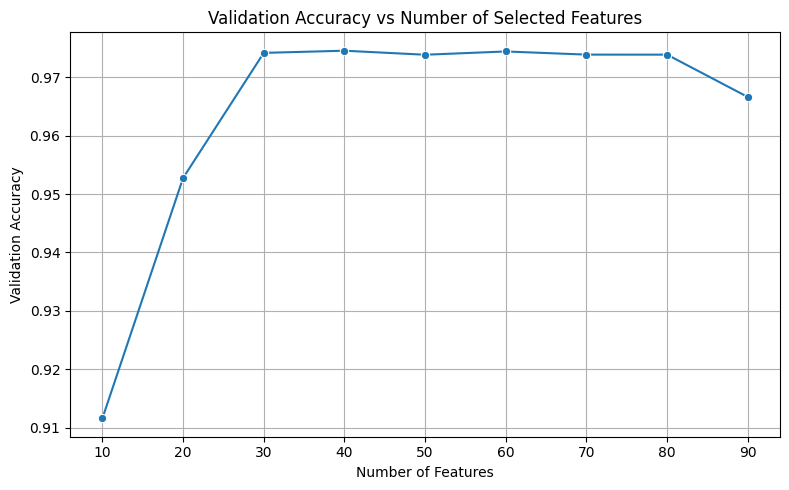

In [19]:
results_df = pd.DataFrame(results, columns=['num_features', 'val_accuracy'])
plt.figure(figsize=(8,5))
sns.lineplot(data=results_df, x='num_features', y='val_accuracy', marker='o')
plt.title("Validation Accuracy vs Number of Selected Features")
plt.xlabel("Number of Features")
plt.ylabel("Validation Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
results_df

,num_features,val_accuracy
0,10,0.911589
1,20,0.952751
2,30,0.974181
3,40,0.974551
4,50,0.973862
5,60,0.974422
6,70,0.973883
7,80,0.973877
8,90,0.966630


In [21]:
# Convert to list of dicts
results_dict = results_df.to_dict(orient='records')

# Save to local hard drive (same folder as script, or change path as needed)
output_path = 'results/FI/results_mi_tuning.json'

with open(output_path, 'w') as f:
    json.dump(results_dict, f, indent=4)